# 04 Evaluation

**Stage 3.** Evaluate every model from the scores files alone.

**How to read a Qini curve.** Sort users from the highest score to the lowest. The curve shows the extra outcomes caused by treatment among the top share of users, as a share of the whole population. A random order gives a straight line from zero to the average effect. A model is useful only where its curve bends above that line. The Qini coefficient is the area between the two, in extra outcomes per user. We compare models with it.

**Hypothesis H1.** At the same budget, uplift targeting delivers more incremental conversions than response targeting. We test each uplift learner against the response baseline with a paired bootstrap, where every resample scores all models on the same rows. We run 3 comparisons per outcome, so p values are multiplied by 3 (Bonferroni).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
RESULTS, REPORT = ROOT / "results", ROOT / "report"
RESULTS.mkdir(exist_ok=True); REPORT.mkdir(exist_ok=True)

from uplift.data import FEATURES, TREATMENT, OUTCOMES, make_splits, take, treated_share_ok, TRAIN_SIZES
from uplift import metrics as m

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
NAMES = {"response": "Response baseline", "s": "S-learner", "t": "T-learner", "x": "X-learner"}
COLORS = {"response": "#7a7a7a", "s": "#1c7293", "t": "#f2a93b", "x": "#0b3d5c"}
N_BOOT = 200
s5 = pd.read_parquet(RESULTS / "scores_5m.parquet")
y = {o: s5[o].to_numpy() for o in OUTCOMES}; t = s5[TREATMENT].to_numpy()
print(f"{len(s5):,} held out users | average effect: visit {y['visit'][t==1].mean() - y['visit'][t==0].mean():.4f}, conversion {y['conversion'][t==1].mean() - y['conversion'][t==0].mean():.5f}")

2,000,000 held out users | average effect: visit 0.0100, conversion 0.00117


## Qini curves, headline run at 5M training rows

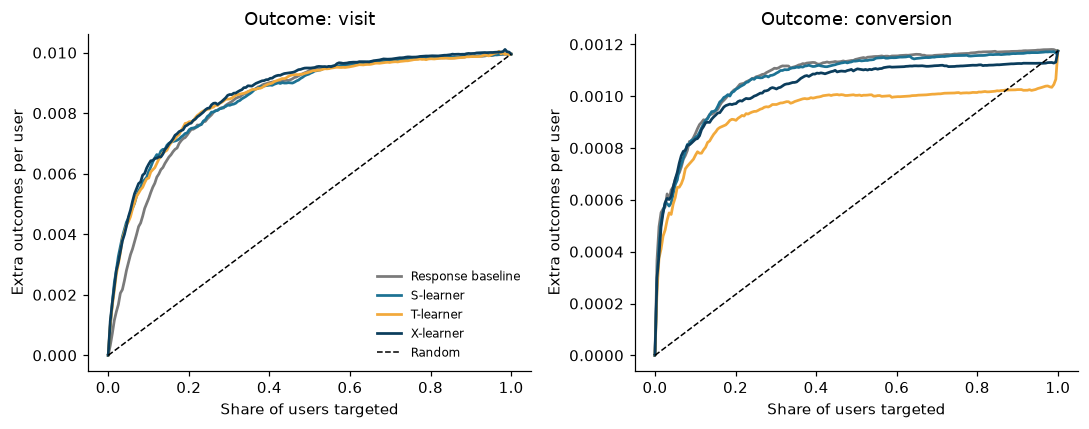

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, outcome in zip(axes, OUTCOMES):
    for mod in NAMES:
        x_, q_ = m.qini_curve(y[outcome], t, s5[f"{mod}_{outcome}"])
        ax.plot(x_, q_, color=COLORS[mod], label=NAMES[mod], lw=1.8)
    ate = y[outcome][t == 1].mean() - y[outcome][t == 0].mean()
    ax.plot([0, 1], [0, ate], "--", color="black", lw=1, label="Random")
    ax.set_title(f"Outcome: {outcome}"); ax.set_xlabel("Share of users targeted"); ax.set_ylabel("Extra outcomes per user")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "qini_curves_5m.png", dpi=200); fig.savefig(REPORT / "qini_curves.png", dpi=200); plt.show()

## Qini coefficients with 95 percent confidence intervals, and the H1 test

In [3]:
results, tests = {}, []
for outcome in OUTCOMES:
    sc = {mod: s5[f"{mod}_{outcome}"].to_numpy() for mod in NAMES}
    boot = m.bootstrap_metrics(y[outcome], t, sc, n_boot=N_BOOT)
    ci = m.bootstrap_ci(boot)
    point = {mod: m.qini_coefficient(y[outcome], t, v) for mod, v in sc.items()}
    tab = pd.DataFrame({"qini_coef": point, "ci_lo": ci["lo"], "ci_hi": ci["hi"],
                        "auuc": {mod: m.auuc(y[outcome], t, v) for mod, v in sc.items()}})
    for frac in (0.1, 0.2, 0.3):
        tab[f"extra_per_1000_at_{int(frac*100)}pct"] = {mod: m.incremental_at(y[outcome], t, v, frac) for mod, v in sc.items()}
    results[outcome] = tab
    tab.round(6).to_csv(RESULTS / f"qini_results_{outcome}_5m.csv")
    for mod in ("s", "t", "x"):
        r = m.paired_difference(boot, mod, "response", point[mod], point["response"])
        tests.append(dict(outcome=outcome, model=NAMES[mod], diff_vs_response=r["diff"], ci_lo=r["lo"], ci_hi=r["hi"],
                          p_one_sided=r["p_one_sided"], p_bonferroni=min(1.0, r["p_one_sided"] * 3)))
tests = pd.DataFrame(tests)
tests.round(6).to_csv(RESULTS / "h1_tests_5m.csv", index=False)
display(results["visit"].round(5)); display(results["conversion"].round(6)); tests.round(5)

,qini_coef,ci_lo,ci_hi,auuc,extra_per_1000_at_10pct,extra_per_1000_at_20pct,extra_per_1000_at_30pct
response,0.00340,0.00315,0.00373,0.00838,51.67112,36.78466,27.78260
s,0.00356,0.00331,0.00384,0.00853,60.69994,37.23835,27.53880
t,0.00358,0.00333,0.00389,0.00856,58.61973,38.60032,28.23576
x,0.00369,0.00343,0.00402,0.00866,63.00331,38.16431,28.69258


,qini_coef,ci_lo,ci_hi,auuc,extra_per_1000_at_10pct,extra_per_1000_at_20pct,extra_per_1000_at_30pct
response,0.000488,0.000418,0.000568,0.001075,8.532021,5.133836,3.686804
s,0.000479,0.000407,0.000564,0.001066,8.435520,5.127523,3.624522
t,0.000356,0.000261,0.000439,0.000943,7.689516,4.528976,3.223900
x,0.000445,0.000361,0.000527,0.001032,8.330752,4.852229,3.432944


,outcome,model,diff_vs_response,ci_lo,ci_hi,p_one_sided,p_bonferroni
0,visit,S-learner,0.00016,0.00009,0.00023,0.00498,0.01493
1,visit,T-learner,0.00018,-0.00009,0.00046,0.10945,0.32836
2,visit,X-learner,0.00029,0.00002,0.00053,0.02488,0.07463
3,conversion,S-learner,-0.00001,-0.00002,0.00001,0.80100,1.00000
4,conversion,T-learner,-0.00013,-0.00021,-0.00006,1.00000,1.00000
5,conversion,X-learner,-0.00004,-0.00009,0.00001,0.94030,1.00000


In [4]:
for outcome in OUTCOMES:
    ok = tests[(tests.outcome == outcome) & (tests.ci_lo > 0) & (tests.p_bonferroni < 0.05)]
    print(f"{outcome}: H1 supported for {len(ok)} of 3 learners ->", ", ".join(ok.model) if len(ok) else "none")

visit: H1 supported for 1 of 3 learners -> S-learner
conversion: H1 supported for 0 of 3 learners -> none


## Sanity test with a planted effect

To trust our own evaluation code we plant an effect we know and check we find it. We keep the real features and treatment, replace the outcome with a synthetic one where treatment only helps users with high `f0`, and check that the oracle score scores highest, a random score scores near zero, and a T-learner trained on a separate slice recovers the effect. The same idea is in the unit tests, where the exact area is known.

In [5]:
from uplift.learners import TLearner
from uplift.pipeline import BASE_PARAMS
kept = json.load(open(RESULTS / "kept_features.json"))
df = pd.read_parquet(ROOT / "data" / "criteo.parquet")
test_ids, pool_ids = make_splits(len(df))
rng = np.random.default_rng(7)
def planted(ids):
    d = take(df, ids)
    tau = 0.05 * (d["f0"] > d["f0"].median()).to_numpy()
    d["fake"] = (rng.random(len(d)) < 0.05 + tau * d[TREATMENT].to_numpy()).astype(int)
    return d, tau
tr, _ = planted(pool_ids[:500_000]); te, tau_te = planted(test_ids[:500_000])
tl = TLearner().fit(tr[kept], tr[TREATMENT], tr["fake"]).predict_uplift(te[kept])
yy, tt = te["fake"].to_numpy(), te[TREATMENT].to_numpy()
rows = {"oracle (true effect)": tau_te, "T-learner": tl, "random": rng.random(len(te)), "reversed oracle": -tau_te}
sanity = pd.Series({k: m.qini_coefficient(yy, tt, v) for k, v in rows.items()}, name="qini_coef")
sanity.round(6).to_csv(RESULTS / "sanity_planted_effect.csv")
print("correlation of T-learner with the true effect:", round(float(np.corrcoef(tl, tau_te)[0, 1]), 3))
sanity.round(5)

correlation of T-learner with the true effect: 0.753


oracle (true effect)    0.00632
T-learner               0.00596
random                 -0.00013
reversed oracle        -0.00602
Name: qini_coef, dtype: float64

## Error analysis

**Observed uplift by decile.** Users are grouped into 10 equal groups by predicted uplift. A good model shows the highest real uplift in decile 1, falling towards zero or below in decile 10. Uplift here is measured on real outcomes, so it is not a prediction.

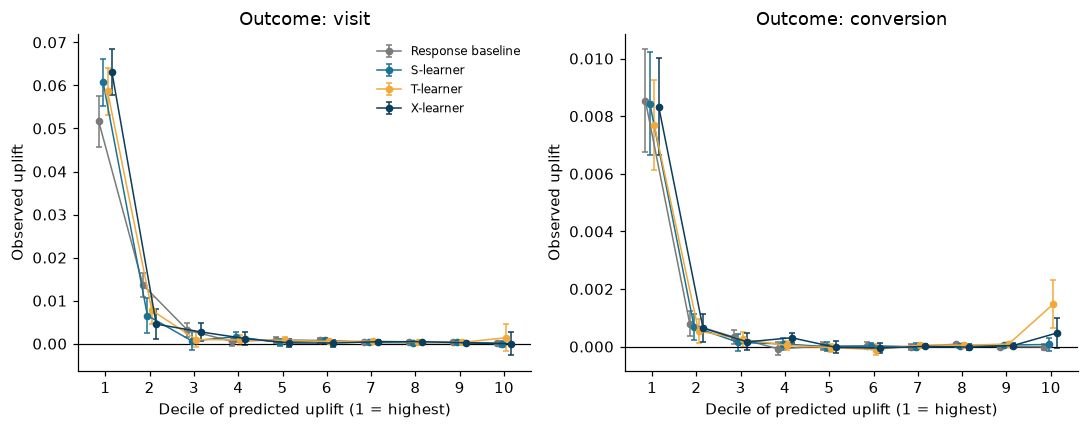

,decile,n,n_treated,n_control,rate_treated,rate_control,uplift,se,mean_score
0,1,200000,173077,26923,0.28657,0.22795,0.05862,0.00278,0.06549
1,2,200000,169875,30125,0.07767,0.06991,0.00776,0.00161,0.01019
2,3,200000,169550,30450,0.02436,0.02338,0.00098,0.00094,0.00296
3,4,200000,169444,30556,0.00932,0.00844,0.00088,0.00057,0.00114
4,5,200000,169159,30841,0.00491,0.00412,0.00079,0.00040,0.00058
5,6,200000,169691,30309,0.00256,0.00201,0.00055,0.00029,0.00032
6,7,200000,169649,30351,0.00146,0.00086,0.00060,0.00019,0.00018
7,8,200000,169542,30458,0.00113,0.00076,0.00037,0.00018,0.00012
8,9,200000,169784,30216,0.00088,0.00056,0.00031,0.00015,0.00005
9,10,200000,169550,30450,0.07115,0.06975,0.00140,0.00159,-0.00409


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
dec = {}
for ax, outcome in zip(axes, OUTCOMES):
    for mod in NAMES:
        d = m.uplift_by_decile(y[outcome], t, s5[f"{mod}_{outcome}"])
        dec[(outcome, mod)] = d
        ax.errorbar(d["decile"] + {"response": -0.15, "s": -0.05, "t": 0.05, "x": 0.15}[mod], d["uplift"], yerr=1.96 * d["se"],
                    fmt="o-", ms=4, lw=1, color=COLORS[mod], label=NAMES[mod], capsize=2)
    ax.axhline(0, color="black", lw=0.8); ax.set_xticks(range(1, 11))
    ax.set_title(f"Outcome: {outcome}"); ax.set_xlabel("Decile of predicted uplift (1 = highest)"); ax.set_ylabel("Observed uplift")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "uplift_by_decile_5m.png", dpi=200); fig.savefig(REPORT / "uplift_by_decile.png", dpi=200); plt.show()
pd.concat({f"{o}_{mod}": d.round(5) for (o, mod), d in dec.items()}).to_csv(RESULTS / "uplift_by_decile_5m.csv")
dec[("visit", "t")].round(5)

**Stability across seeds.** A single run could be luck. We refit the response baseline and the T-learner on three different random 1M training samples with different model seeds, and compare Qini coefficients on the same holdout. Visits only, to keep it quick.

In [7]:
from lightgbm import LGBMClassifier
best = json.load(open(RESULTS / "best_params.json"))["visit"]
yv, tv = y["visit"], t
rows = []
for seed in (1, 2, 3):
    ids = np.random.default_rng(seed).permutation(pool_ids)[:1_000_000]   # different training sample each time
    tr = take(df, ids)
    p = {**best, "random_state": seed}
    resp = LGBMClassifier(**{**BASE_PARAMS, **p}).fit(tr[kept], tr["visit"]).predict_proba(take(df, test_ids)[kept])[:, 1]
    tl = TLearner(p).fit(tr[kept], tr[TREATMENT], tr["visit"]).predict_uplift(take(df, test_ids)[kept])
    rows.append(dict(seed=seed, response=m.qini_coefficient(yv, tv, resp), t_learner=m.qini_coefficient(yv, tv, tl)))
stab = pd.DataFrame(rows)
stab.round(6).to_csv(RESULTS / "seed_stability_visit.csv", index=False)
print("spread across seeds (max minus min):", (stab.drop(columns="seed").max() - stab.drop(columns="seed").min()).round(6).to_dict())
stab.round(6)

spread across seeds (max minus min): {'response': 8e-06, 't_learner': 0.00034}


,seed,response,t_learner
0,1,0.003398,0.003312
1,2,0.003406,0.003217
2,3,0.003402,0.003557


## Data size curve

Our own question: how much data does uplift targeting need before it beats response targeting? We read the Qini coefficient of each model at 100k, 500k, 1M and 5M training rows, always on the same 2M held out users. Bars show 95 percent bootstrap intervals.

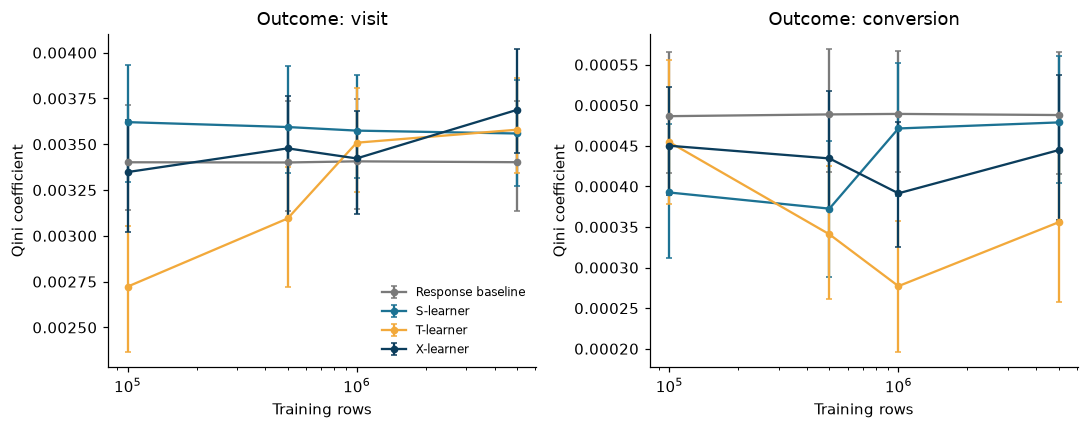

model,response,s,t,x
train_rows,,,,
100000,0.00340,0.00362,0.00272,0.00335
500000,0.00340,0.00359,0.00309,0.00348
1000000,0.00341,0.00357,0.00351,0.00342
5000000,0.00340,0.00356,0.00358,0.00369


In [8]:
sizes = {"100k": 100_000, "500k": 500_000, "1m": 1_000_000, "5m": 5_000_000}
curve = []
for outcome in OUTCOMES:
    for label, n in sizes.items():
        sz = pd.read_parquet(RESULTS / f"scores_{label}.parquet")
        sc = {mod: sz[f"{mod}_{outcome}"].to_numpy() for mod in NAMES}
        boot = m.bootstrap_metrics(sz[outcome].to_numpy(), sz[TREATMENT].to_numpy(), sc, n_boot=100)
        ci = m.bootstrap_ci(boot)
        for mod in NAMES:
            curve.append(dict(outcome=outcome, train_rows=n, model=mod, qini_coef=m.qini_coefficient(sz[outcome].to_numpy(), sz[TREATMENT].to_numpy(), sc[mod]),
                              ci_lo=ci.loc[mod, "lo"], ci_hi=ci.loc[mod, "hi"]))
curve = pd.DataFrame(curve)
curve.round(6).to_csv(RESULTS / "size_curve.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, outcome in zip(axes, OUTCOMES):
    for mod in NAMES:
        c = curve[(curve.outcome == outcome) & (curve.model == mod)]
        ax.errorbar(c.train_rows, c.qini_coef, yerr=[c.qini_coef - c.ci_lo, c.ci_hi - c.qini_coef], fmt="o-", color=COLORS[mod], label=NAMES[mod], capsize=2, lw=1.5, ms=4)
    ax.set_xscale("log"); ax.set_title(f"Outcome: {outcome}"); ax.set_xlabel("Training rows"); ax.set_ylabel("Qini coefficient")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "size_curve.png", dpi=200); fig.savefig(REPORT / "size_curve.png", dpi=200); plt.show()
curve[curve.outcome == "visit"].pivot(index="train_rows", columns="model", values="qini_coef").round(5)

## Relative uplift by response group (R7)

**The explanation we test.** If users who respond more also gain more in proportion, then ranking by response ranks by uplift almost as well, and the response baseline is hard to beat. In that case the relative uplift, uplift divided by the control rate, would be about the same in every response group.

**Method.** We sort the holdout users by `response_visit` from high to low and cut them into 10 groups of equal size (group 1 has the highest response). In each group we compute the control rate, the treated rate, the observed uplift (treated rate minus control rate) and the relative uplift (uplift divided by control rate). The 95 percent interval for the uplift is uplift plus or minus 1.96 times `sqrt(p1*(1-p1)/n1 + p0*(1-p0)/n0)`, the same standard error as in the sleeping dogs check. We also compute the Spearman rank correlation between `response_visit` and `s_visit` over all users. Outcome: visits.

**Why the ratio needs its own interval.** The relative uplift divides by the control rate, and in the low response groups the control rate rests on very few visits. A change of a handful of control visits moves the ratio a lot, so the uplift interval says little about how noisy the ratio is. We therefore build a bootstrap interval for the relative uplift itself: in each group we redraw the number of visits in both arms from a binomial distribution (2000 draws, fixed seed), recompute the ratio each time and take the 2.5 and 97.5 percent points. The intervals are saved in `results/relative_uplift_bootstrap.csv`. To judge flatness we use only groups with at least 100 control visits, because below that the intervals are too wide to tell anything.

In [9]:
ru = m.uplift_by_decile(y["visit"], t, s5["response_visit"], bins=10)
ru["relative_uplift"] = ru["uplift"] / ru["rate_control"]
ru["ci_lo"] = ru["uplift"] - 1.96 * ru["se"]
ru["ci_hi"] = ru["uplift"] + 1.96 * ru["se"]
ru_table = ru.rename(columns={"rate_control": "control_rate", "rate_treated": "treated_rate"})[
    ["decile", "n", "control_rate", "treated_rate", "uplift", "ci_lo", "ci_hi", "relative_uplift"]]
ru_table.round(8).to_csv(RESULTS / "relative_uplift_response_deciles.csv", index=False)

rho = s5["response_visit"].corr(s5["s_visit"], method="spearman")
pd.DataFrame({"pair": ["response_visit vs s_visit"], "spearman": [rho]}).round(6).to_csv(
    RESULTS / "relative_uplift_rank_correlation.csv", index=False)
print(f"Spearman rank correlation between response_visit and s_visit over {len(s5):,} users: {rho:.4f}")
ru_table.round(6)

Spearman rank correlation between response_visit and s_visit over 2,000,000 users: 0.9625


,decile,n,control_rate,treated_rate,uplift,ci_lo,ci_hi,relative_uplift
0,1,200000,0.322676,0.374347,0.051671,0.045736,0.057606,0.160133
1,2,200000,0.055561,0.069224,0.013663,0.010784,0.016542,0.245904
2,3,200000,0.016319,0.019529,0.003209,0.001635,0.004784,0.196653
3,4,200000,0.007132,0.007679,0.000547,-0.000480,0.001574,0.076679
4,5,200000,0.003287,0.004183,0.000896,0.000186,0.001606,0.272461
5,6,200000,0.001618,0.002380,0.000762,0.000254,0.001271,0.471042
6,7,200000,0.000856,0.001150,0.000294,-0.000073,0.000660,0.342984
7,8,200000,0.000464,0.000813,0.000349,0.000071,0.000627,0.752540
8,9,200000,0.000265,0.000577,0.000313,0.000096,0.000529,1.180694
9,10,200000,0.000329,0.000389,0.000060,-0.000164,0.000285,0.183707


In [10]:
# Bootstrap interval of the relative uplift. Both arms are resampled in every decile, so the error in the control rate is included.
N_BOOT_REL, SEED_REL = 2000, 20240
rng = np.random.default_rng(SEED_REL)
boot_rows = []
for r in ru.itertuples():
    x1 = rng.binomial(r.n_treated, r.rate_treated, N_BOOT_REL) / r.n_treated
    x0 = rng.binomial(r.n_control, r.rate_control, N_BOOT_REL) / r.n_control
    ok = x0 > 0                                   # a draw with no control events has no ratio and is skipped (counted below)
    rel_draws = (x1[ok] - x0[ok]) / x0[ok]
    boot_rows.append(dict(decile=r.decile, rel_lo=np.percentile(rel_draws, 2.5), rel_hi=np.percentile(rel_draws, 97.5), skipped=int((~ok).sum())))
rel_boot = pd.DataFrame(boot_rows)
rel_boot[["decile", "rel_lo", "rel_hi"]].round(6).to_csv(RESULTS / "relative_uplift_bootstrap.csv", index=False)
print(f"{N_BOOT_REL} binomial bootstrap draws per decile, seed {SEED_REL}; draws skipped for zero control events: {int(rel_boot['skipped'].sum())}")

ru["control_events"] = (ru["rate_control"] * ru["n_control"]).round().astype(int)
ru["rel_lo"], ru["rel_hi"] = rel_boot["rel_lo"].to_numpy(), rel_boot["rel_hi"].to_numpy()
ru["rel_width"] = ru["rel_hi"] - ru["rel_lo"]
ru[["decile", "n_control", "control_events", "relative_uplift", "rel_lo", "rel_hi"]].round(3)

2000 binomial bootstrap draws per decile, seed 20240; draws skipped for zero control events: 1


,decile,n_control,control_events,relative_uplift,rel_lo,rel_hi
0,1,27994,9033,0.160,0.139,0.181
1,2,29481,1638,0.246,0.188,0.313
2,3,30148,492,0.197,0.093,0.317
3,4,30845,220,0.077,-0.061,0.243
4,5,30727,101,0.272,0.043,0.579
5,6,30281,49,0.471,0.120,1.017
6,7,30374,26,0.343,-0.059,1.093
7,8,30191,14,0.753,0.104,2.378
8,9,30223,8,1.181,0.205,4.815
9,10,30415,10,0.184,-0.316,1.870


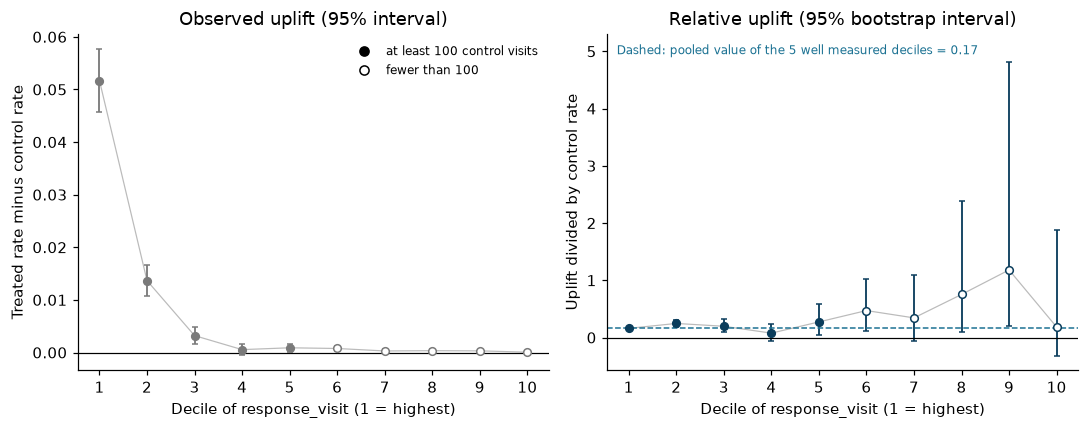

In [11]:
MIN_EVENTS = 100   # a decile is "well measured" if it has at least this many control visits
ru["enough"] = ru["control_events"] >= MIN_EVENTS
good, thin = ru[ru["enough"]], ru[~ru["enough"]]

# Pooled relative uplift of the well measured deciles: deciles are equal in size, so weight them by n
pooled = (good["n"] * good["uplift"]).sum() / (good["n"] * good["rate_control"]).sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for ax, col, lo, hi, title, ylab in [
        (axes[0], "uplift", "ci_lo", "ci_hi", "Observed uplift (95% interval)", "Treated rate minus control rate"),
        (axes[1], "relative_uplift", "rel_lo", "rel_hi", "Relative uplift (95% bootstrap interval)", "Uplift divided by control rate")]:
    for sub, filled in [(good, True), (thin, False)]:
        ax.errorbar(sub["decile"], sub[col], yerr=[sub[col] - sub[lo], sub[hi] - sub[col]], fmt="o", ms=5, lw=1.2, capsize=2,
                    color=COLORS["response"] if ax is axes[0] else COLORS["x"], mfc=None if filled else "white")
    ax.plot(ru["decile"], ru[col], lw=0.8, color="#bbbbbb", zorder=0)
    ax.axhline(0, color="black", lw=0.8); ax.set_xticks(range(1, 11)); ax.set_xlabel("Decile of response_visit (1 = highest)")
    ax.set_title(title); ax.set_ylabel(ylab)
axes[1].axhline(pooled, color=COLORS["s"], lw=1, ls="--")
axes[1].text(0.02, 0.97, f"Dashed: pooled value of the {len(good)} well measured deciles = {pooled:.2f}", transform=axes[1].transAxes, ha="left", va="top", fontsize=8, color=COLORS["s"])
axes[0].plot([], [], "o", color="k", label=f"at least {MIN_EVENTS} control visits"); axes[0].plot([], [], "o", mfc="white", color="k", label=f"fewer than {MIN_EVENTS}")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_ylim(top=max(5.3, ru["rel_hi"].max() * 1.1))
fig.tight_layout(); fig.savefig(RESULTS / "relative_uplift.png", dpi=200); plt.show()

**Reading the figure.** Left: the observed uplift with its 95 percent interval in each response group. Right: the relative uplift with its 95 percent bootstrap interval, which includes the error in the control rate. Hollow markers are groups with fewer than 100 control visits. The dashed line is the pooled relative uplift of the groups with at least 100 control visits.

In [12]:
from IPython.display import Markdown, display

rel_g = good.set_index("decile")["relative_uplift"]
lo_d, hi_d = int(rel_g.idxmin()), int(rel_g.idxmax())
ratio = float(rel_g.max() / rel_g.min())
inside = (good["rel_lo"] <= pooled) & (pooled <= good["rel_hi"])
n_in, n_good = int(inside.sum()), len(good)
common = bool(good["rel_lo"].max() <= good["rel_hi"].min())   # do all intervals share at least one value?
outside = ", ".join(str(int(d)) for d in good.loc[~inside, "decile"])

no_one = outside.count(",") == 0
if n_in == n_good:
    overlap = f"all {n_good} of their bootstrap intervals contain their pooled value of {pooled:.2f}"
else:
    overlap = f"{n_in} of their {n_good} bootstrap intervals contain their pooled value of {pooled:.2f} ({'decile' if no_one else 'deciles'} {outside} {'does' if no_one else 'do'} not)"
s1 = (f"Among the {n_good} deciles with at least {MIN_EVENTS} control visits, relative uplift runs from {rel_g.min():.2f} (decile {lo_d}) to {rel_g.max():.2f} (decile {hi_d}), "
      f"a ratio of {ratio:.1f}, and {overlap}, while the other {len(thin)} deciles have too few control visits (as few as {int(thin['control_events'].min())}) and intervals too wide to tell, "
      f"so the data neither clearly show a flat pattern nor clearly reject one.")

verdict = "weakly supported" if (n_in == n_good and common) else "inconclusive"
s2 = (f"For H1 this means the explanation that users who respond more also gain proportionally more, so that response ranking is hard to beat, is {verdict}: "
      f"the Spearman rank correlation between response_visit and s_visit is {rho:.2f}, so the two rankings are very similar, but that does not show that uplift grows in proportion to response.")
text = f"**Conclusion:** {s1} {s2}"
display(Markdown(text)); print(text)

**Conclusion:** Among the 5 deciles with at least 100 control visits, relative uplift runs from 0.08 (decile 4) to 0.27 (decile 5), a ratio of 3.6, and 4 of their 5 bootstrap intervals contain their pooled value of 0.17 (decile 2 does not), while the other 5 deciles have too few control visits (as few as 8) and intervals too wide to tell, so the data neither clearly show a flat pattern nor clearly reject one. For H1 this means the explanation that users who respond more also gain proportionally more, so that response ranking is hard to beat, is inconclusive: the Spearman rank correlation between response_visit and s_visit is 0.96, so the two rankings are very similar, but that does not show that uplift grows in proportion to response.

**Conclusion:** Among the 5 deciles with at least 100 control visits, relative uplift runs from 0.08 (decile 4) to 0.27 (decile 5), a ratio of 3.6, and 4 of their 5 bootstrap intervals contain their pooled value of 0.17 (decile 2 does not), while the other 5 deciles have too few control visits (as few as 8) and intervals too wide to tell, so the data neither clearly show a flat pattern nor clearly reject one. For H1 this means the explanation that users who respond more also gain proportionally more, so that response ranking is hard to beat, is inconclusive: the Spearman rank correlation between response_visit and s_visit is 0.96, so the two rankings are very similar, but that does not show that uplift grows in proportion to response.
